### Setup e Verifica Ambiente

In [1]:
import os
import torch
import monai
import pandas as pd
import nibabel as nib

print(f"Versione PyTorch: {torch.__version__}")
print(f"Versione MONAI: {monai.__version__}")

# Verifica disponibilità GPU / CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo di calcolo in uso: {device}")

if device.type == "cuda":
    print(f"GPU rilevata: {torch.cuda.get_device_name(0)}")

Versione PyTorch: 2.14.1+cpu
Versione MONAI: 1.6.1
Dispositivo di calcolo in uso: cpu


### Preparazione del Dataset Tabellare per MONAI

In [2]:
import glob

# 1. Carichiamo il dataset tabellare clinico pulito
csv_path = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/oasis_features_hippocampus.csv"
df = pd.read_csv(csv_path)

# 2. Mappiamo gli ID con i percorsi reali dei file .img nel file system
data_dir = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data"
image_paths = glob.glob(f"{data_dir}/**/RAW/*.img", recursive=True)

# Creiamo un dizionario ID -> File Path (prendendo la prima scansione disponibile per ogni soggetto)
path_dict = {}
for p in image_paths:
    sub_id = os.path.basename(p).split('_mpr')[0]
    if sub_id not in path_dict:
        path_dict[sub_id] = p

# 3. Creiamo la lista di dizionari per MONAI [{'image': path, 'label': 0/1}]
data_dicts = []
for idx, row in df.iterrows():
    sub_id = row['ID']
    if sub_id in path_dict and not pd.isna(row['CDR']):
        data_dicts.append({
            'image': path_dict[sub_id],
            'label': 1 if row['CDR'] > 0 else 0
        })

print(f"Totale Campioni pronti per MONAI 3D: {len(data_dicts)}")
print(f"Esempio primo elemento:\n{data_dicts[0]}")

Totale Campioni pronti per MONAI 3D: 25
Esempio primo elemento:
{'image': 'C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data\\raw\\disc1\\OAS1_0001_MR1\\RAW\\OAS1_0001_MR1_mpr-1_anon.img', 'label': 0}


#### Definizione delle Trasformazioni 3D di MONAI

In [7]:
from monai.transforms import (
    Compose, 
    LoadImaged, 
    EnsureChannelFirstd, 
    ScaleIntensityd,
    ResizeD,
    EnsureTyped
)

from monai.data import NibabelReader, Dataset, DataLoader
import matplotlib.pyplot as plt

# Pipeline di trasformazione per le immagini 3D
train_transforms = Compose([
    LoadImaged(keys=["image"], reader=NibabelReader()), # Usa NibabelReader per il formato ANALYZE
    EnsureChannelFirstd(keys=["image"]),          # Aggiunge il canale [C, H, W, D]
    ScaleIntensityd(keys=["image"]),                  # Normalizza l'intensità dei pixel tra 0 e 1
    ResizeD(keys=["image"], spatial_size=(96, 96, 96)), # Standardizza le dimensioni 3D a 96x96x96
    EnsureTyped(keys=["image", "label"])              # Converte in Tensor PyTorch
])

print("Pipeline delle trasformazioni 3D MONAI definita con successo!")

Pipeline delle trasformazioni 3D MONAI definita con successo!


### Dataset, DataLoader e Test del Tensor 3D

Dataset e DataLoader MONAI 3D creati correttamente!

Caricamento ed elaborazione del primo batch 3D in corso...
Forma del tensore immagini [Batch, Canali, X, Y, Z]: torch.Size([2, 1, 96, 96, 96])
Forma del tensore etichette: torch.Size([2])
Etichette del batch: [0, 0]


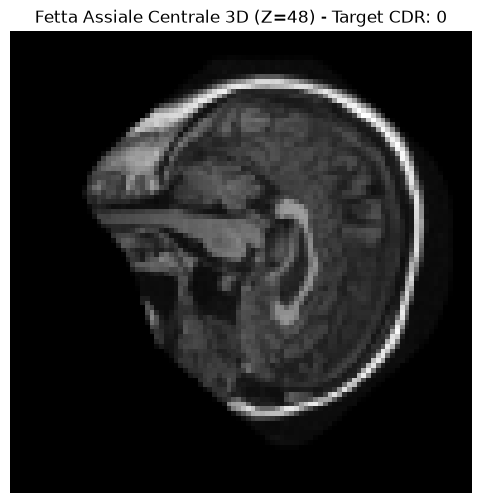

In [8]:
# 1. Creazione del Dataset MONAI con applicazione delle trasformazioni 3D
train_ds = Dataset(data=data_dicts, transform=train_transforms)

# 2. DataLoader di PyTorch per la gestione dei batch (batch_size=2 per la CPU)
train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=0)

print("Dataset e DataLoader MONAI 3D creati correttamente!")

# 3. Test sul primo batch per verificare la forma (shape) dei dati 3D
print("\nCaricamento ed elaborazione del primo batch 3D in corso...")
first_batch = next(iter(train_loader))

images = first_batch["image"]
labels = first_batch["label"]

print(f"Forma del tensore immagini [Batch, Canali, X, Y, Z]: {images.shape}")
print(f"Forma del tensore etichette: {labels.shape}")
print(f"Etichette del batch: {labels.tolist()}")

# 4. Visualizzazione fetta 2D dal volume 3D
image_3d = images[0, 0].cpu().numpy()
slice_idx = image_3d.shape[2] // 2

plt.figure(figsize=(6, 6))
plt.imshow(image_3d[:, :, slice_idx], cmap="gray")
plt.title(f"Fetta Assiale Centrale 3D (Z={slice_idx}) - Target CDR: {labels[0].item()}")
plt.axis("off")
plt.show()

### Definizione della Rete Convoluzionale 3D (MONAI DenseNet121 o UNet/CNN3D)

In [9]:
from monai.networks.nets import DenseNet121
import torch.nn as nn 
import torch.optim as optim

# 1. Definizione dell'architettura 3D CNN (DenseNet121 adattata a volumi 3D a 1 canale)
model = DenseNet121(
    spatial_dims=3,          # Input 3D
    in_channels=1,           # 1 canale di intensità (scansione T1 MRI)
    out_channels=2           # 2 classi di output: 0 (Sano/CDR=0) vs 1 (Demenza/CDR>0)
).to(device)

print(f"Modello 3D DenseNet121 inizializzato su {device}")

# 2. Funzione di perdita con CrossEntropy Loss e Ottimizzatore Adam
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# Verifica rapida del passaggio (forward pass) su un batch
with torch.no_grad():
    sample_outputs = model(images.to(device))
    print(f"Forma dell'output del modello per un batch di test: {sample_outputs.shape}")

Modello 3D DenseNet121 inizializzato su cpu
Forma dell'output del modello per un batch di test: torch.Size([2, 2])


### Loop di Addestramento di Prova (Training Loop su 3 Epochs)

In [10]:
import time

num_epochs = 3
print("--- Inizio Addestramento 3D CNN ---")

for epoch in range(num_epochs):
    start_time = time.time()
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_data in train_loader:
        inputs = batch_data["image"].to(device)
        labels = batch_data["label"].to(device)

        # Azzeriamo i gradienti dell'ottimizzatore
        optimizer.zero_grad()

        # Forward + Backward + Optimize
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Statistiche di addestramento
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data)
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct.double() / total
    elapsed = time.time() - start_time

    print(f"Epoca [{epoch+1}/{num_epochs}] - Tempo: {elapsed:.2f}s - Loss: {epoch_loss:.4f} - Acc: {epoch_acc * 100:.2f}%")

print("\nLoop di addestramento 3D testato con successo!")

--- Inizio Addestramento 3D CNN ---
Epoca [1/3] - Tempo: 57.90s - Loss: 0.7319 - Acc: 44.00%
Epoca [2/3] - Tempo: 54.90s - Loss: 0.6536 - Acc: 68.00%
Epoca [3/3] - Tempo: 57.86s - Loss: 0.6199 - Acc: 60.00%

Loop di addestramento 3D testato con successo!
